In [16]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import requests
import zipfile
import io

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [17]:
# Read the uploaded Excel file

df = pd.read_excel("mydata.xlsx")

# Display confirmation
print("Dataset loaded successfully!")

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display first five rows
#display(df.head())

# 1. Display dataset dimensions
print("Dataset Shape:", df.shape)

# 2. Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Display dataset information
print("\nDataset Information:")
df.info()

# 4. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# 6. Display statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset loaded successfully!
Dataset shape: (13611, 17)
Dataset Shape: (13611, 17)

Column Names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity      

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


Number of records in each bean class:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


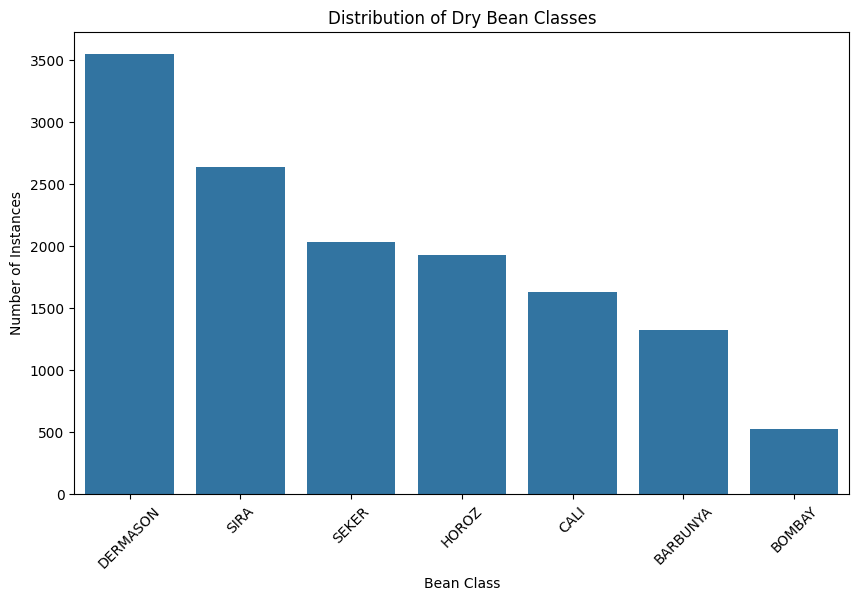

In [18]:
# Count the number of records in each class

class_counts = df["Class"].value_counts()

print("Number of records in each bean class:")
print(class_counts)

# Plot class distribution

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Class",
    order=df["Class"].value_counts().index
)

plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean Class")
plt.ylabel("Number of Instances")
plt.xticks(rotation=45)

plt.show()

In [19]:
# Separate independent and dependent variables

X = df.drop("Class", axis=1)

y = df["Class"]

# Display the shapes

print("Independent Variables (X):", X.shape)

print("Dependent Variable (y):", y.shape)

# Display feature names

print("\nInput Features:")
print(X.columns.tolist())

# Display target classes

print("\nTarget Classes:")
print(y.unique())

print("\nNumber of Classes:", y.nunique())

Independent Variables (X): (13611, 16)
Dependent Variable (y): (13611,)

Input Features:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Target Classes:
['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']

Number of Classes: 7


In [20]:
# Import train_test_split

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# Display training and testing percentages

print("\nTraining Percentage:", round(len(X_train) / len(X) * 100, 2), "%")
print("Testing Percentage:", round(len(X_test) / len(X) * 100, 2), "%")

Training Features Shape: (10888, 16)
Testing Features Shape: (2723, 16)
Training Target Shape: (10888,)
Testing Target Shape: (2723,)

Training Percentage: 79.99 %
Testing Percentage: 20.01 %


In [21]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling parameters to testing data
X_test_scaled = scaler.transform(X_test)

# Display scaling information
print("FEATURE SCALING SUMMARY")
print("=" * 35)

print(f"Original Training Shape : {X_train.shape}")
print(f"Original Testing Shape  : {X_test.shape}")

print(f"\nScaled Training Shape   : {X_train_scaled.shape}")
print(f"Scaled Testing Shape    : {X_test_scaled.shape}")

print("\nTraining Data Mean (first 5 features):")
print(np.round(X_train_scaled.mean(axis=0)[:5], 4))

print("\nTraining Data Std (first 5 features):")
print(np.round(X_train_scaled.std(axis=0)[:5], 4))

print("\nFeature scaling completed successfully!")

FEATURE SCALING SUMMARY
Original Training Shape : (10888, 16)
Original Testing Shape  : (2723, 16)

Scaled Training Shape   : (10888, 16)
Scaled Testing Shape    : (2723, 16)

Training Data Mean (first 5 features):
[ 0. -0.  0. -0. -0.]

Training Data Std (first 5 features):
[1. 1. 1. 1. 1.]

Feature scaling completed successfully!


In [22]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Initialize Logistic Regression model
lr_model = LogisticRegression(
    solver="lbfgs",
    max_iter=2000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Generate predictions
y_pred_lr = lr_model.predict(X_test_scaled)

# Calculate class probabilities
y_prob_lr = lr_model.predict_proba(X_test_scaled)

# Evaluate model accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

# Display model performance
print("LOGISTIC REGRESSION - MODEL RESULTS")
print("=" * 45)

print(f"Algorithm          : Logistic Regression")
print(f"Solver             : {lr_model.solver}")
print(f"Maximum Iterations : {lr_model.max_iter}")
print(f"Training Samples   : {X_train_scaled.shape[0]}")
print(f"Testing Samples    : {X_test_scaled.shape[0]}")
print(f"Number of Features : {X_train_scaled.shape[1]}")
print(f"Number of Classes  : {len(lr_model.classes_)}")

print("\nMODEL PERFORMANCE")
print("-" * 45)
print(f"Test Accuracy      : {lr_accuracy:.4f} ({lr_accuracy * 100:.2f}%)")

print("\nPREDICTION COMPARISON (FIRST 10)")
print("-" * 45)

comparison_df = pd.DataFrame({
    "Actual Class": y_test.iloc[:10].values,
    "Predicted Class": y_pred_lr[:10],
    "Correct Prediction": (
        y_test.iloc[:10].values == y_pred_lr[:10]
    )
})

display(comparison_df)

print("\nPrediction Probability Shape:", y_prob_lr.shape)
print("Model training and prediction completed successfully!")

LOGISTIC REGRESSION - MODEL RESULTS
Algorithm          : Logistic Regression
Solver             : lbfgs
Maximum Iterations : 2000
Training Samples   : 10888
Testing Samples    : 2723
Number of Features : 16
Number of Classes  : 7

MODEL PERFORMANCE
---------------------------------------------
Test Accuracy      : 0.9214 (92.14%)

PREDICTION COMPARISON (FIRST 10)
---------------------------------------------


,Actual Class,Predicted Class,Correct Prediction
0,DERMASON,DERMASON,True
1,BOMBAY,BOMBAY,True
2,SIRA,SIRA,True
3,SEKER,SEKER,True
4,BARBUNYA,BARBUNYA,True
5,SEKER,SEKER,True
6,DERMASON,DERMASON,True
7,SIRA,SIRA,True
8,BARBUNYA,CALI,False
9,HOROZ,HOROZ,True



Prediction Probability Shape: (2723, 7)
Model training and prediction completed successfully!


In [23]:

# Import Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Initialize Decision Tree model
dt_model = DecisionTreeClassifier(
    criterion="gini",
    splitter="best",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

# Generate predictions
y_pred_dt = dt_model.predict(X_test)

# Calculate prediction probabilities
y_prob_dt = dt_model.predict_proba(X_test)

# Evaluate model accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)

# Display model information
print("DECISION TREE CLASSIFIER - MODEL RESULTS")
print("=" * 48)

print(f"Algorithm          : Decision Tree")
print(f"Splitting Criterion: {dt_model.criterion}")
print(f"Maximum Depth      : {dt_model.max_depth}")
print(f"Training Samples   : {X_train.shape[0]}")
print(f"Testing Samples    : {X_test.shape[0]}")
print(f"Number of Features : {X_train.shape[1]}")
print(f"Number of Classes  : {len(dt_model.classes_)}")
print(f"Tree Depth         : {dt_model.get_depth()}")
print(f"Number of Leaves   : {dt_model.get_n_leaves()}")

# Display model performance
print("\nMODEL PERFORMANCE")
print("-" * 48)
print(f"Test Accuracy      : {dt_accuracy:.4f} ({dt_accuracy * 100:.2f}%)")

# Compare actual and predicted values
print("\nPREDICTION COMPARISON (FIRST 10)")
print("-" * 48)

comparison_df = pd.DataFrame({
    "Actual Class": y_test.iloc[:10].values,
    "Predicted Class": y_pred_dt[:10],
    "Correct Prediction": (
        y_test.iloc[:10].values == y_pred_dt[:10]
    )
})

display(comparison_df)

print("\nPrediction Probability Shape:", y_prob_dt.shape)
print("Decision Tree training and prediction completed successfully!")


DECISION TREE CLASSIFIER - MODEL RESULTS
Algorithm          : Decision Tree
Splitting Criterion: gini
Maximum Depth      : None
Training Samples   : 10888
Testing Samples    : 2723
Number of Features : 16
Number of Classes  : 7
Tree Depth         : 29
Number of Leaves   : 692

MODEL PERFORMANCE
------------------------------------------------
Test Accuracy      : 0.8920 (89.20%)

PREDICTION COMPARISON (FIRST 10)
------------------------------------------------


,Actual Class,Predicted Class,Correct Prediction
0,DERMASON,DERMASON,True
1,BOMBAY,BOMBAY,True
2,SIRA,SIRA,True
3,SEKER,SEKER,True
4,BARBUNYA,BARBUNYA,True
5,SEKER,SEKER,True
6,DERMASON,DERMASON,True
7,SIRA,SIRA,True
8,BARBUNYA,CALI,False
9,HOROZ,HOROZ,True



Prediction Probability Shape: (2723, 7)
Decision Tree training and prediction completed successfully!


In [24]:

# Import K-Nearest Neighbors Classifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Initialize KNN model
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="uniform",
    algorithm="auto",
    metric="euclidean"
)

# Train the model
knn_model.fit(X_train_scaled, y_train)

# Generate predictions
y_pred_knn = knn_model.predict(X_test_scaled)

# Calculate prediction probabilities
y_prob_knn = knn_model.predict_proba(X_test_scaled)

# Evaluate model accuracy
knn_accuracy = accuracy_score(y_test, y_pred_knn)

# Display model information
print("K-NEAREST NEIGHBORS - MODEL RESULTS")
print("=" * 48)

print(f"Algorithm          : K-Nearest Neighbors")
print(f"Number of Neighbors: {knn_model.n_neighbors}")
print(f"Distance Metric    : {knn_model.metric}")
print(f"Weight Function    : {knn_model.weights}")
print(f"Training Samples   : {X_train_scaled.shape[0]}")
print(f"Testing Samples    : {X_test_scaled.shape[0]}")
print(f"Number of Features : {X_train_scaled.shape[1]}")
print(f"Number of Classes  : {len(knn_model.classes_)}")

# Display model performance
print("\nMODEL PERFORMANCE")
print("-" * 48)
print(f"Test Accuracy      : {knn_accuracy:.4f} ({knn_accuracy * 100:.2f}%)")

# Compare actual and predicted values
print("\nPREDICTION COMPARISON (FIRST 10)")
print("-" * 48)

comparison_df = pd.DataFrame({
    "Actual Class": y_test.iloc[:10].values,
    "Predicted Class": y_pred_knn[:10],
    "Correct Prediction": (
        y_test.iloc[:10].values == y_pred_knn[:10]
    )
})

display(comparison_df)

print("\nPrediction Probability Shape:", y_prob_knn.shape)
print("KNN training and prediction completed successfully!")


K-NEAREST NEIGHBORS - MODEL RESULTS
Algorithm          : K-Nearest Neighbors
Number of Neighbors: 5
Distance Metric    : euclidean
Weight Function    : uniform
Training Samples   : 10888
Testing Samples    : 2723
Number of Features : 16
Number of Classes  : 7

MODEL PERFORMANCE
------------------------------------------------
Test Accuracy      : 0.9166 (91.66%)

PREDICTION COMPARISON (FIRST 10)
------------------------------------------------


,Actual Class,Predicted Class,Correct Prediction
0,DERMASON,DERMASON,True
1,BOMBAY,BOMBAY,True
2,SIRA,SIRA,True
3,SEKER,SEKER,True
4,BARBUNYA,BARBUNYA,True
5,SEKER,SEKER,True
6,DERMASON,DERMASON,True
7,SIRA,SIRA,True
8,BARBUNYA,CALI,False
9,HOROZ,HOROZ,True



Prediction Probability Shape: (2723, 7)
KNN training and prediction completed successfully!


In [25]:

# Import Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# Initialize Gaussian Naive Bayes model
nb_model = GaussianNB(
    priors=None,
    var_smoothing=1e-9
)

# Train the model
nb_model.fit(X_train_scaled, y_train)

# Generate predictions
y_pred_nb = nb_model.predict(X_test_scaled)

# Calculate prediction probabilities
y_prob_nb = nb_model.predict_proba(X_test_scaled)

# Evaluate model accuracy
nb_accuracy = accuracy_score(y_test, y_pred_nb)

# Display model information
print("GAUSSIAN NAIVE BAYES - MODEL RESULTS")
print("=" * 48)

print(f"Algorithm          : Gaussian Naive Bayes")
print(f"Variance Smoothing : {nb_model.var_smoothing}")
print(f"Training Samples   : {X_train_scaled.shape[0]}")
print(f"Testing Samples    : {X_test_scaled.shape[0]}")
print(f"Number of Features : {X_train_scaled.shape[1]}")
print(f"Number of Classes  : {len(nb_model.classes_)}")

# Display model performance
print("\nMODEL PERFORMANCE")
print("-" * 48)
print(f"Test Accuracy      : {nb_accuracy:.4f} ({nb_accuracy * 100:.2f}%)")

# Compare actual and predicted values
print("\nPREDICTION COMPARISON (FIRST 10)")
print("-" * 48)

comparison_df = pd.DataFrame({
    "Actual Class": y_test.iloc[:10].values,
    "Predicted Class": y_pred_nb[:10],
    "Correct Prediction": (
        y_test.iloc[:10].values == y_pred_nb[:10]
    )
})

display(comparison_df)

print("\nPrediction Probability Shape:", y_prob_nb.shape)
print("Gaussian Naive Bayes training and prediction completed successfully!")


GAUSSIAN NAIVE BAYES - MODEL RESULTS
Algorithm          : Gaussian Naive Bayes
Variance Smoothing : 1e-09
Training Samples   : 10888
Testing Samples    : 2723
Number of Features : 16
Number of Classes  : 7

MODEL PERFORMANCE
------------------------------------------------
Test Accuracy      : 0.8979 (89.79%)

PREDICTION COMPARISON (FIRST 10)
------------------------------------------------


,Actual Class,Predicted Class,Correct Prediction
0,DERMASON,DERMASON,True
1,BOMBAY,BOMBAY,True
2,SIRA,SIRA,True
3,SEKER,SEKER,True
4,BARBUNYA,BARBUNYA,True
5,SEKER,SEKER,True
6,DERMASON,DERMASON,True
7,SIRA,SIRA,True
8,BARBUNYA,CALI,False
9,HOROZ,HOROZ,True



Prediction Probability Shape: (2723, 7)
Gaussian Naive Bayes training and prediction completed successfully!


In [26]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)

print("Support Vector Machine Classifier")
print("---------------------------------")
print("Model Training Completed Successfully!")

print("\nPredicted Classes (First 10):")
print(y_pred_svm[:10])

print("\nActual Classes (First 10):")
print(y_test.iloc[:10].values)

print("\nPrediction Probability Shape:", y_prob_svm.shape)

Support Vector Machine Classifier
---------------------------------
Model Training Completed Successfully!

Predicted Classes (First 10):
['DERMASON' 'BOMBAY' 'SIRA' 'SEKER' 'BARBUNYA' 'SEKER' 'DERMASON' 'SIRA'
 'CALI' 'HOROZ']

Actual Classes (First 10):
['DERMASON' 'BOMBAY' 'SIRA' 'SEKER' 'BARBUNYA' 'SEKER' 'DERMASON' 'SIRA'
 'BARBUNYA' 'HOROZ']

Prediction Probability Shape: (2723, 7)


In [27]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Store predictions and probabilities of all five models
model_predictions = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "Decision Tree": (y_pred_dt, y_prob_dt),
    "K-Nearest Neighbors": (y_pred_knn, y_prob_knn),
    "Gaussian Naive Bayes": (y_pred_nb, y_prob_nb),
    "Support Vector Machine": (y_pred_svm, y_prob_svm)
}

# Calculate evaluation metrics
results = []

for model_name, (y_pred, y_prob) in model_predictions.items():

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC Score": roc_auc_score(
            y_test, y_prob,
            multi_class="ovr",
            average="weighted"
        ),
        "Precision": precision_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),
        "MCC Score": matthews_corrcoef(y_test, y_pred)
    })

# Create and display comparison table
results_df = pd.DataFrame(results)

print("CLASSIFICATION MODEL PERFORMANCE COMPARISON")
print("---------------------------------------------")

display(results_df.round(4))

CLASSIFICATION MODEL PERFORMANCE COMPARISON
---------------------------------------------


,Model,Accuracy,AUC Score,Precision,Recall,F1 Score,MCC Score
0,Logistic Regression,0.9214,0.9934,0.9222,0.9214,0.9216,0.9050
1,Decision Tree,0.8920,0.9334,0.8917,0.8920,0.8916,0.8696
2,K-Nearest Neighbors,0.9166,0.9812,0.9174,0.9166,0.9168,0.8992
3,Gaussian Naive Bayes,0.8979,0.9902,0.9007,0.8979,0.8981,0.8773
4,Support Vector Machine,0.9221,0.9937,0.9224,0.9221,0.9222,0.9059


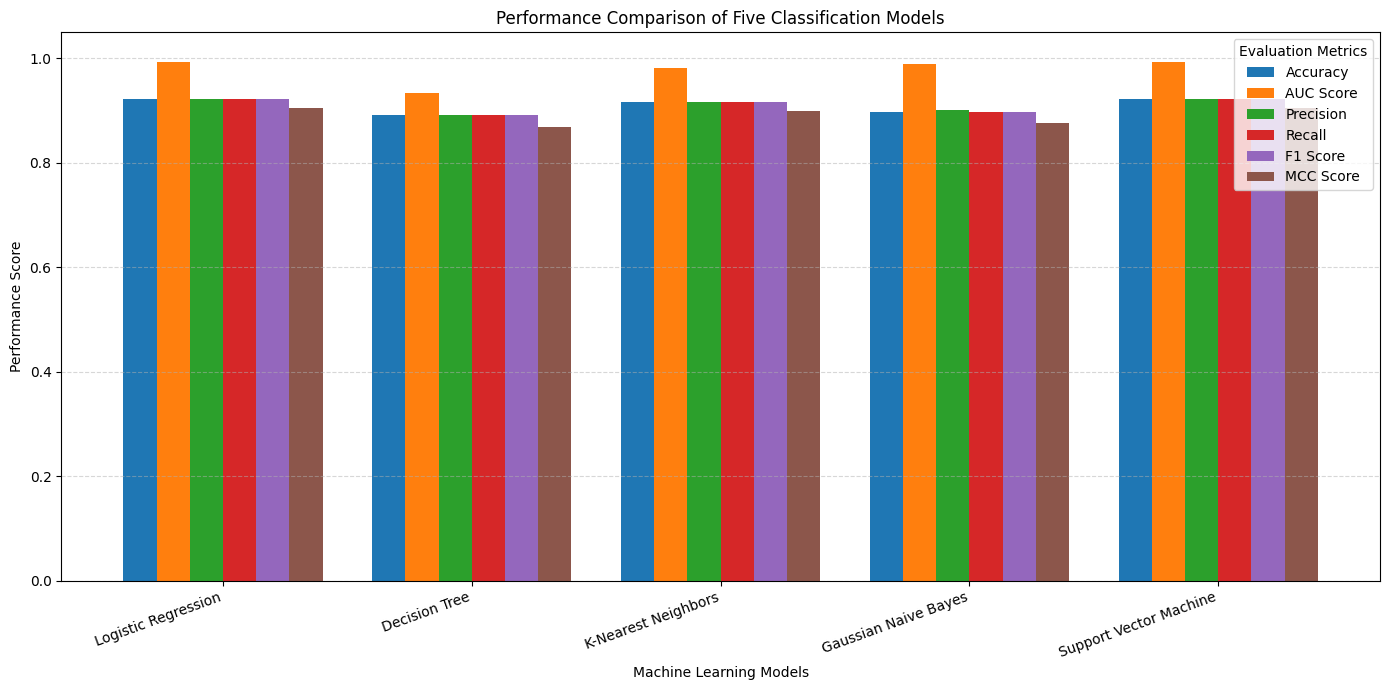

In [28]:
# Visualize model performance using evaluation metrics

metrics = [
    "Accuracy",
    "AUC Score",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC Score"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title("Performance Comparison of Five Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.05)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [29]:
# Identify the best-performing classification model

best_model = results_df.loc[results_df["Accuracy"].idxmax()]

print("BEST PERFORMING MODEL")
print("---------------------")
print("Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("AUC Score:", round(best_model["AUC Score"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))
print("MCC Score:", round(best_model["MCC Score"], 4))

BEST PERFORMING MODEL
---------------------
Model: Support Vector Machine
Accuracy: 0.9221
AUC Score: 0.9937
Precision: 0.9224
Recall: 0.9221
F1 Score: 0.9222
MCC Score: 0.9059


## Conclusion

In this project, five machine learning classification algorithms were implemented to classify dry bean varieties using 16 numerical features.

The following algorithms were evaluated:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

The models were evaluated using Accuracy, AUC, Precision, Recall, F1-Score, and Matthews Correlation Coefficient (MCC).

Among the five classifiers, **Support Vector Machine (SVM)** achieved the highest accuracy of **92.21%** and an AUC score of **0.9937**.

Based on the evaluation results, SVM demonstrated the best overall classification performance on the test dataset.

This project provided practical experience in data preprocessing, feature scaling, multiclass classification, model evaluation, and performance comparison.